# Implementando makemore

* Qué es un modelo de bigramas estadístico auto-regresivo y cómo implementamos uno?
* Los bigramas son secuencias de dos carácteres, por ejemplo `ab` o `gh`.

## Explorando el dataset

In [1]:
dataset = open('data/city_names_puny.txt', 'r').read().split('\n')
dataset # punycode
puny = [x for x in dataset if 'xn--' in x]
nopuny = [x for x in dataset if 'xn--' not in x]

In [2]:
import idna

# def utf8_to_punycode(text: str) -> str:
#     """Encodes a UTF-8 string to its Punycode representation."""
#     return idna.encode(text).decode('ascii')

def punyencode(text: str) -> str:
    """Encodes a UTF-8 string to its Punycode representation, handling spaces by encoding each word separately."""
    
    return " ".join([idna.encode(word).decode('ascii') for word in text.split()])
    
def punydecode(punycode: str) -> str:
    """Decodes a Punycode string back to UTF-8."""
    #return idna.decode(punycode)
    return " ".join([idna.decode(word) for word in punycode.split()])

def process_name(name):
    name = name.lower()
    for n in name.split():
        if len(n) < 2:
            return ''
    try:
        return punyencode(name)
    except:
        #print(f'Cant convert {name}')
        return ''

In [37]:
# s = set()
# for nombre in dataset:
#     for c in nombre:
#         s.add(c)
%timeit set([c for nombre in dataset for c in nombre])

31.4 ms ± 689 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [40]:
%%timeit
s = set()
for nombre in dataset:
    for c in nombre:
        s.add(c)

43.9 ms ± 1.75 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [41]:
s

{' ',
 '-',
 '.',
 '0',
 '1',
 '2',
 '3',
 '4',
 '5',
 '6',
 '7',
 '8',
 '9',
 'a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z'}

## Generando bigramas

In [43]:
for d in ['la plata']+ dataset[:3]:
    example = ['*'] + list(d) + ['*']
    for c1, c2 in zip(example, example[1:]):
        print(c1,c2)

* l
l a
a  
  p
p l
l a
a t
t a
a *
* h
h e
e i
i s
s t
t -
- o
o p
p -
- d
d e
e n
n -
- b
b e
e r
r g
g *
* h
h a
a r
r c
c h
h i
i e
e s
s *
* f
f l
l o
o r
r e
e n
n n
n e
e s
s *


## Contando bigramas

In [47]:
import numpy as np
charset = ['*'] + sorted(list(set([y for x in dataset for y in x])))
ctoi = {c:i for i, c in enumerate(charset)}
itoc = {i:c for i, c in enumerate(charset)}

In [56]:
ctoi

{'*': 0,
 ' ': 1,
 '-': 2,
 '.': 3,
 '0': 4,
 '1': 5,
 '2': 6,
 '3': 7,
 '4': 8,
 '5': 9,
 '6': 10,
 '7': 11,
 '8': 12,
 '9': 13,
 'a': 14,
 'b': 15,
 'c': 16,
 'd': 17,
 'e': 18,
 'f': 19,
 'g': 20,
 'h': 21,
 'i': 22,
 'j': 23,
 'k': 24,
 'l': 25,
 'm': 26,
 'n': 27,
 'o': 28,
 'p': 29,
 'q': 30,
 'r': 31,
 's': 32,
 't': 33,
 'u': 34,
 'v': 35,
 'w': 36,
 'x': 37,
 'y': 38,
 'z': 39}

In [67]:
bigram_count = np.zeros((len(charset), len(charset))).astype(int)
bigram_count

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(40, 40))

In [62]:
ctoi['l']

25

In [68]:
for d in dataset:  # <== remove [:10] to run for all examples
    example = ['*'] + list(d) + ['*']
    for c1, c2 in zip(example, example[1:]):
        bigram_count[ctoi[c1], ctoi[c2]] += 1
bigram_count

array([[    1,     0,     0, ..., 23496,  1142,  1367],
       [    0,     0,     0, ...,  6162,   218,   257],
       [    0,     0, 29157, ...,  1111,   935,  1073],
       ...,
       [  476,    54,   227, ...,    33,    38,    18],
       [ 5019,   841,  1159, ...,    35,   320,    83],
       [  972,   321,   781, ...,    30,   380,   501]], shape=(40, 40))

In [66]:
bigram_count[0,ctoi['j']]

np.int64(0)

(np.float64(-0.5), np.float64(39.5), np.float64(39.5), np.float64(-0.5))

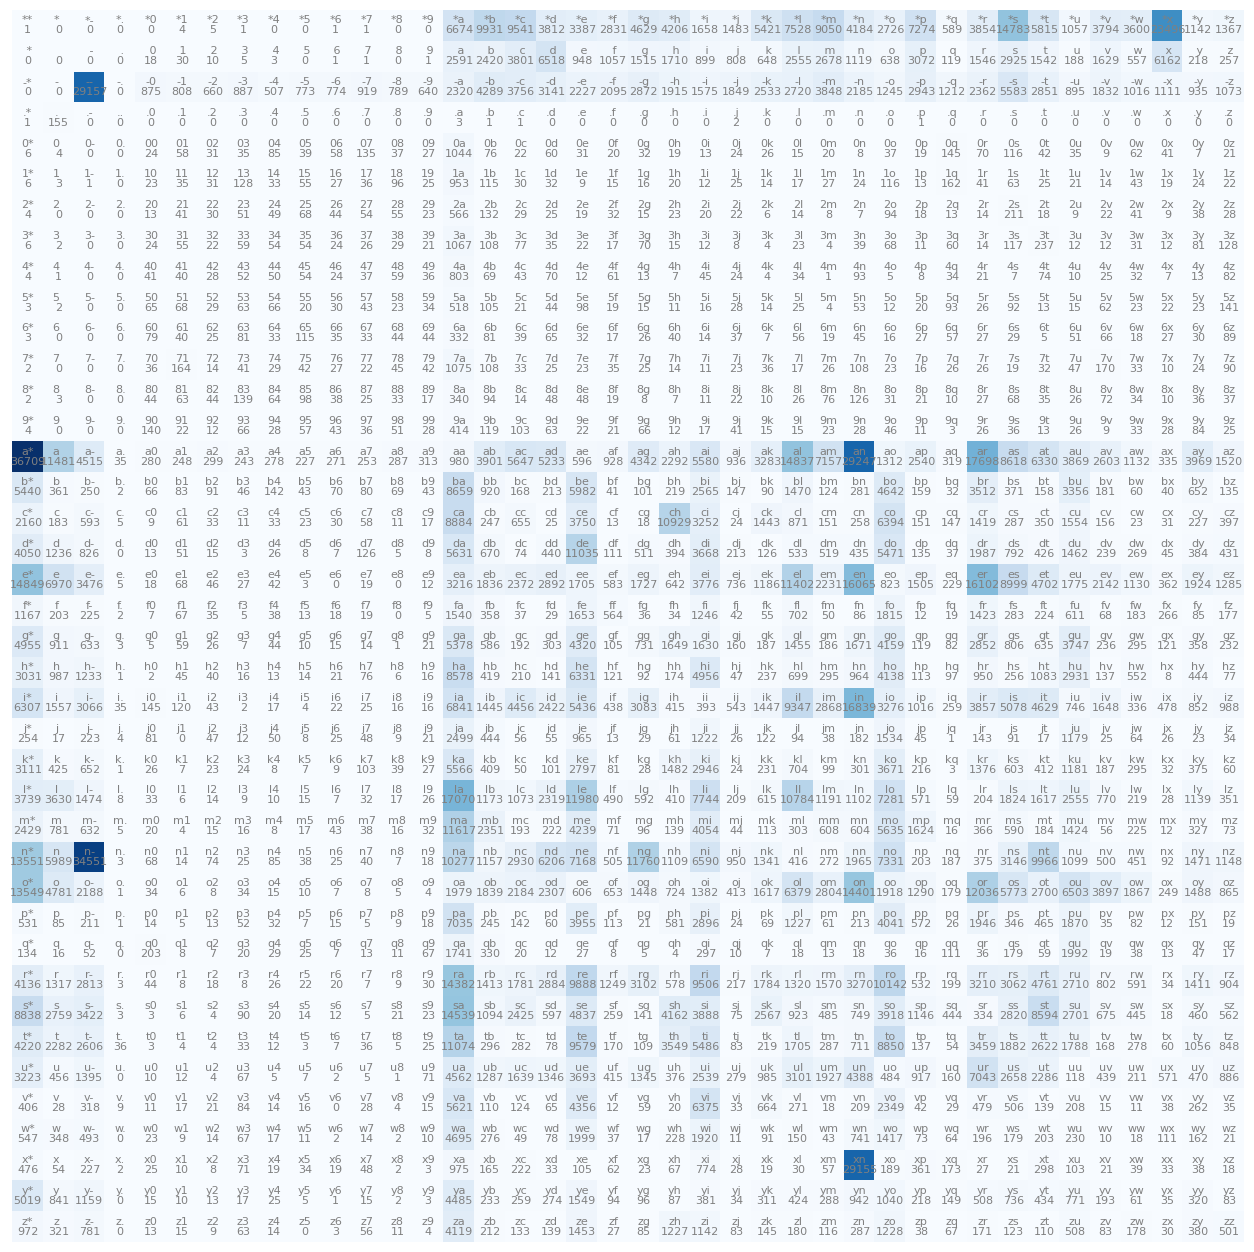

In [69]:
import matplotlib.pyplot as plt
#%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(bigram_count, cmap='Blues')
for i in range(len(charset)):
    for j in range(len(charset)):
        chars = itoc[i]+itoc[j]
        plt.text(j, i, chars,ha='center', va='bottom', color='grey', fontsize=8)
        plt.text(j, i, bigram_count[i,j],ha='center', va='top', color='grey', fontsize=8)
plt.axis('off')

## Usando una matriz para almacenar las ocurrencias

In [ ]:
import matplotlib.pyplot as plt
#%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(bigram_count, cmap='Blues')
for i in range(len(charset)):
    for j in range(len(charset)):
        chars = itoc[i]+itoc[j]
        plt.text(j, i, chars,ha='center', va='bottom', color='grey', fontsize=8)
        plt.text(j, i, bigram_count[i,j],ha='center', va='top', color='grey', fontsize=8)
plt.axis('off')

## Convertir la matriz de cuentas en una matriz de probabilidades

In [77]:
p = bigram_count[0]/sum(bigram_count[0])
p

array([6.95192742e-06, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 2.78077097e-05, 3.47596371e-05, 6.95192742e-06,
       0.00000000e+00, 0.00000000e+00, 6.95192742e-06, 6.95192742e-06,
       0.00000000e+00, 0.00000000e+00, 4.63971636e-02, 6.90395912e-02,
       6.63283395e-02, 2.65007473e-02, 2.35461782e-02, 1.96809065e-02,
       3.21804720e-02, 2.92398067e-02, 1.15262957e-02, 1.03097084e-02,
       3.76863986e-02, 5.23341096e-02, 6.29149432e-02, 2.90868643e-02,
       1.89509542e-02, 5.05683201e-02, 4.09468525e-03, 2.67927283e-02,
       1.02770343e-01, 4.04254580e-02, 7.34818728e-03, 2.63756126e-02,
       2.50269387e-02, 1.63342487e-01, 7.93910112e-03, 9.50328479e-03])

In [85]:
p[ctoi['a']]

np.float64(0.046397163613611875)

In [94]:
np.random.choice(charset, 1, p=p, replace=True)

array(['s'], dtype='<U1')

In [107]:
def generate(bigram_count):
    new = []
    p = bigram_count[0]
    p = p/p.sum()
    draw = np.random.choice(charset, 1, p=p, replace=True)[0]
    while draw != '*':
        p = bigram_count[ctoi[draw]]
        p = p/p.sum()
        #p = [1/40]*40
        draw = np.random.choice(charset, 1, p=p, replace=True)[0]
        new.append(draw)
    return ''.join(new[:-1])

In [108]:
for i in range(10):
    print(generate(bigram_count))

belletlmu
i-vry

o xngre--tosury pisaka
adetz
egbivid
huradb
a
n-l canteviczotozanin
o


## La Negative Log Likelihood loss (NLL loss)

## Model Smoothing

## Sampleando del modelo

## Conclusiones
* En este módulo creamos un modelo de bigramas probabilistico autoregresivo.
* El modelo cuenta las ocurrencias de los bigramas y luego calcula las distribuciones de probabilidad de un carácter dado el carácter anterior.
* Toda la información está contenida en una matriz de probabilidades
* Vimos como calcular que tan bueno o malo es el modelo respecto a nuestro universo de carácteres conocidos (charset) y a un modelo que elige carácteres al azar.
* Esta métrica nos va a acompañar el resto del curso y vamos a volver sobre esto luego.

## Ejercicios
* Generar un modelo de trigramas (intermedio).
  * Pista: En lugar de una matriz, guardar las probabilidades en un tensor tridimensional.